# TexTag: Exploratory Data Analysis

**Dataset:** DTD (Describable Textures Dataset), loaded with `torchvision.datasets.DTD`.
**Goal of this notebook:** understand the images before training, and let what we find decide the preprocessing.

Sections:
1. Load data
2. Class balance
3. Sample grid
4. Look-alike classes
5. Image sizes
6. Bad files check
7. Color stats
8. Augmentation preview
9. Summary

In [1]:
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from textag.data import DATA_DIR, IMAGENET_MEAN, IMAGENET_STD, train_tf

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]   # photos: jpeg keeps the notebook small

def load(path, size=256):
    # open as RGB, shrunk to a thumbnail (keeps the notebook small)
    im = Image.open(path).convert("RGB")
    im.thumbnail((size, size))
    return im

## 1. Load data

DTD comes with official splits. We use **partition 1**: train / val / test.
`transform=None` here so we get the raw images (no resizing yet).

In [2]:
splits = {s: datasets.DTD(DATA_DIR, split=s, partition=1, download=True) for s in ("train", "val", "test")}
classes = splits["train"].classes

for s, d in splits.items():
    print(f"{s:5s}: {len(d):,} images")
print(f"total: {sum(len(d) for d in splits.values()):,} images")
print(f"classes: {len(classes)}")
print(classes)

train: 1,880 images
val  : 1,880 images
test : 1,880 images
total: 5,640 images
classes: 47
['banded', 'blotchy', 'braided', 'bubbly', 'bumpy', 'chequered', 'cobwebbed', 'cracked', 'crosshatched', 'crystalline', 'dotted', 'fibrous', 'flecked', 'freckled', 'frilly', 'gauzy', 'grid', 'grooved', 'honeycombed', 'interlaced', 'knitted', 'lacelike', 'lined', 'marbled', 'matted', 'meshed', 'paisley', 'perforated', 'pitted', 'pleated', 'polka-dotted', 'porous', 'potholed', 'scaly', 'smeared', 'spiralled', 'sprinkled', 'stained', 'stratified', 'striped', 'studded', 'swirly', 'veined', 'waffled', 'woven', 'wrinkled', 'zigzagged']


In [3]:
# one table with every image: path, class, split
rows = []
for s, d in splits.items():
    for path, label in zip(d._image_files, d._labels):
        rows.append({"path": str(path), "label": classes[label], "split": s})
df = pd.DataFrame(rows)
df.assign(path=df.path.map(lambda p: Path(p).name)).head()

,path,label,split
0,banded_0005.jpg,banded,train
1,banded_0011.jpg,banded,train
2,banded_0013.jpg,banded,train
3,banded_0019.jpg,banded,train
4,banded_0021.jpg,banded,train


## 2. Class balance

How many images does each class have? If some classes had far more images, the model could
get high accuracy by just guessing the big classes.

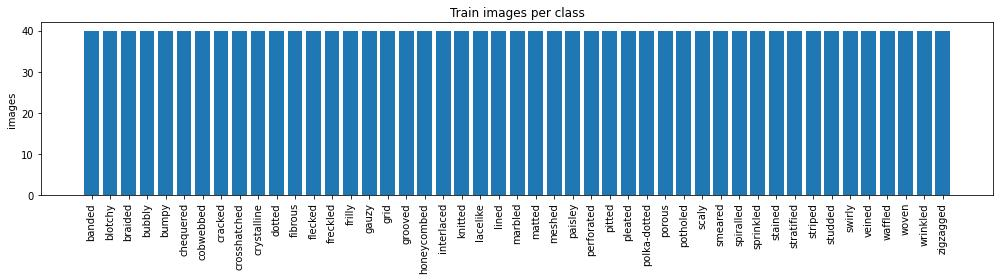

split  test  train   val
min    40.0   40.0  40.0
max    40.0   40.0  40.0


In [4]:
counts = df[df.split == "train"].label.value_counts().sort_index()

plt.figure(figsize=(14, 4))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=90)
plt.ylabel("images")
plt.title("Train images per class")
plt.tight_layout()
plt.show()

print(pd.crosstab(df.label, df.split).describe().loc[["min", "max"]])

**Finding:** every class has exactly 40 images in each split. The data is perfectly balanced.
**Decision:** accuracy is a fair metric, and we don't need class weights in the loss.

## 3. Sample grid

One image per class, so we can see what the model has to tell apart.

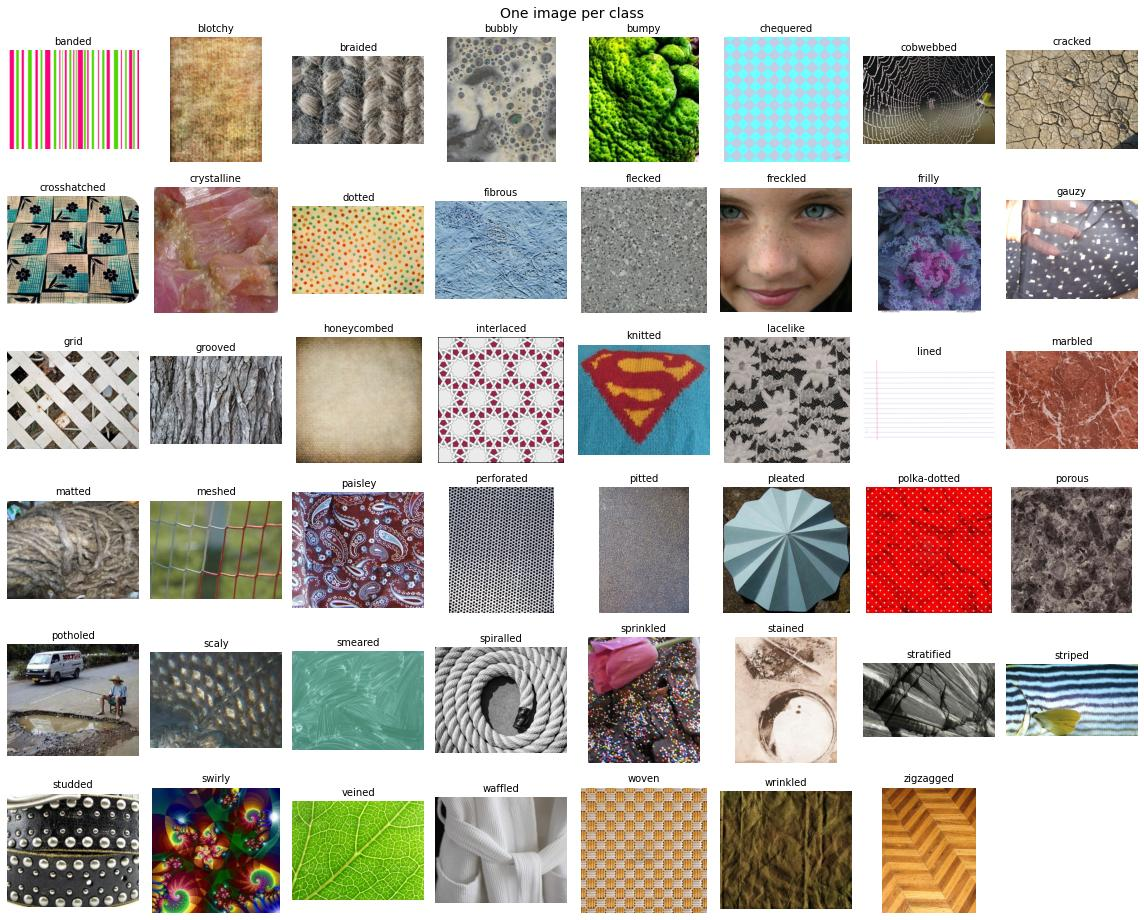

In [5]:
first = df[df.split == "train"].groupby("label").first()

fig, axes = plt.subplots(6, 8, figsize=(16, 13))
for ax in axes.flat:
    ax.axis("off")
for ax, (label, row) in zip(axes.flat, first.iterrows()):
    ax.imshow(load(row.path))
    ax.set_title(label, fontsize=10)
plt.suptitle("One image per class", fontsize=14)
plt.tight_layout()
plt.show()

**Finding:** classes are *patterns*, not materials. "banded" can be fabric, wood or paint.
The model has to learn the shape of the pattern, not the color or the object.

## 4. Look-alike classes

Some class pairs look very similar. These are our guesses for where the model will make mistakes.
We'll check this guess later against the confusion matrix (step 6).

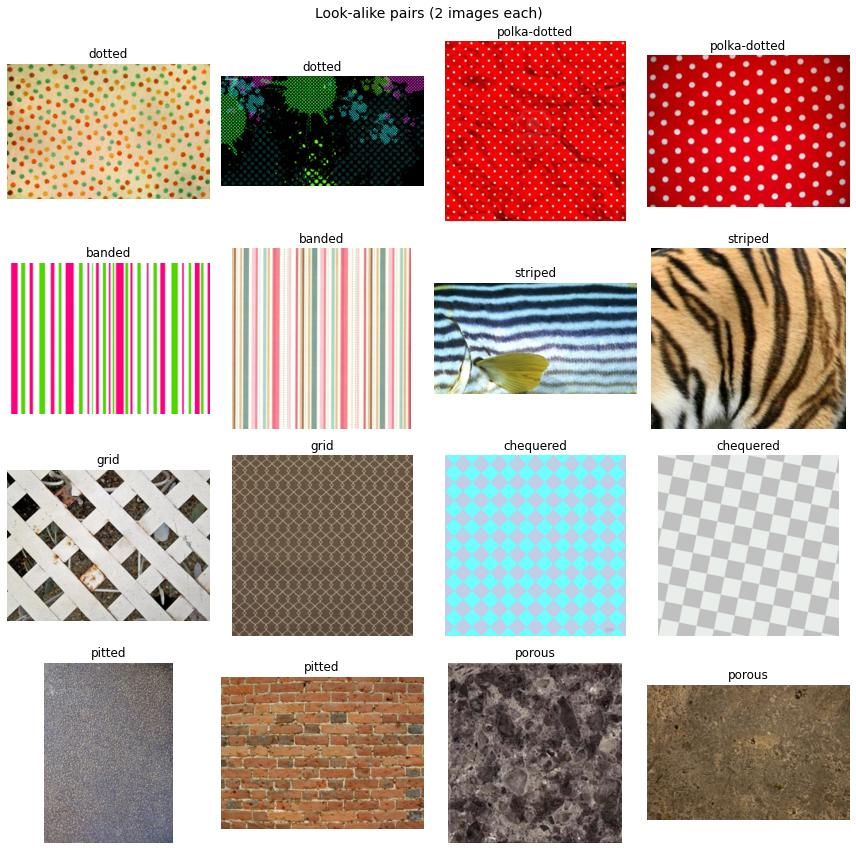

In [6]:
pairs = [("dotted", "polka-dotted"), ("banded", "striped"), ("grid", "chequered"), ("pitted", "porous")]
train = df[df.split == "train"]

fig, axes = plt.subplots(len(pairs), 4, figsize=(12, 3 * len(pairs)))
for r, (a, b) in enumerate(pairs):
    imgs = list(train[train.label == a].path[:2]) + list(train[train.label == b].path[:2])
    names = [a, a, b, b]
    for c, (p, n) in enumerate(zip(imgs, names)):
        axes[r, c].imshow(load(p))
        axes[r, c].set_title(n)
        axes[r, c].axis("off")
plt.suptitle("Look-alike pairs (2 images each)", fontsize=14)
plt.tight_layout()
plt.show()

**Finding:** even a person could mix some of these up. This is the hard part of the dataset,
and with only 40 training images per class it's a good reason to use a **pretrained** model (step 5).

## 5. Image sizes

A neural network needs every image to be the same size. How different are they?

        width  height
count  5640.0  5640.0
mean    496.0   451.0
std     115.0   104.0
min     271.0   231.0
25%     400.0   363.0
50%     497.0   437.0
75%     625.0   515.0
max     900.0   778.0


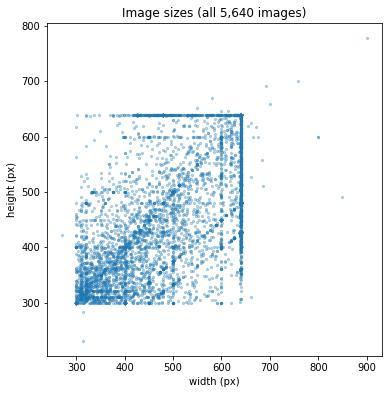

In [7]:
sizes = [Image.open(p).size for p in df.path]   # opening only reads the header, so this is fast
df["width"] = [w for w, h in sizes]
df["height"] = [h for w, h in sizes]

print(df[["width", "height"]].describe().round(0))

plt.figure(figsize=(6, 6))
plt.scatter(df.width, df.height, s=5, alpha=0.3)
plt.xlabel("width (px)")
plt.ylabel("height (px)")
plt.title("Image sizes (all 5,640 images)")
plt.show()

In [8]:
print("smallest side min:", min(df.width.min(), df.height.min()), "px")
print("images with short side < 256 px:", ((df[["width", "height"]].min(axis=1)) < 256).sum())
print("square images:", f"{(df.width == df.height).mean():.0%}")

smallest side min: 231 px
images with short side < 256 px: 1
square images: 9%


**Finding:** most images are between 300 and 640 px per side, but sizes vary a lot, and only 9% are square. All but 1 image have a short side of at least 256 px.
**Decision:** resize the short side to 256, then crop the center 224×224 (the size ResNet was trained on).
So we almost always shrink images and almost never stretch them, which keeps the texture detail.

## 6. Bad files check

The image version of a missing-values check: can every file be opened, and is it a normal RGB image?

In [9]:
bad, modes = [], Counter()
for p in df.path:
    try:
        with Image.open(p) as im:
            modes[im.mode] += 1
            im.verify()
    except Exception as e:
        bad.append((p, str(e)))

print("corrupted files:", len(bad))
print("color modes:", dict(modes))

corrupted files: 0
color modes: {'RGB': 5640}


**Finding:** 0 corrupted files, and all 5,640 images are already RGB (3 channels).
**Decision:** no cleaning needed.

## 7. Color stats

We plan to use a ResNet pretrained on ImageNet. It expects images normalized with ImageNet's mean and std.
Are our textures close to ImageNet's colors? We check a sample of 10 images per class.

In [10]:
sample = df[df.split == "train"].groupby("label").head(10)
pixels = []
for p in sample.path:
    im = Image.open(p).convert("RGB").resize((64, 64))
    pixels.append(np.asarray(im, dtype=np.float32).reshape(-1, 3) / 255)
pixels = np.concatenate(pixels)

stats = pd.DataFrame({
    "DTD mean": pixels.mean(0), "ImageNet mean": IMAGENET_MEAN,
    "DTD std": pixels.std(0), "ImageNet std": IMAGENET_STD,
}, index=["R", "G", "B"]).round(3)
stats

,DTD mean,ImageNet mean,DTD std,ImageNet std
R,0.543,0.485,0.254,0.229
G,0.494,0.456,0.245,0.224
B,0.441,0.406,0.255,0.225


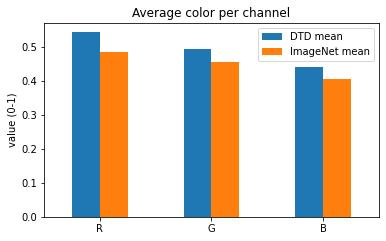

In [11]:
stats[["DTD mean", "ImageNet mean"]].plot.bar(figsize=(6, 3.5), rot=0, title="Average color per channel")
plt.ylabel("value (0-1)")
plt.show()

**Finding:** DTD is slightly brighter than ImageNet (about +0.04 to +0.06 per channel), but close.
**Decision:** use the ImageNet mean/std for normalization. That's what the pretrained weights expect.

## 8. Augmentation preview

With only 40 images per class, the model could memorize the training set. To prevent that, each epoch
we show it a randomly changed version of every image: crop, flip, rotation, color jitter (training only).
Below: one image passed through the training transform 8 times.

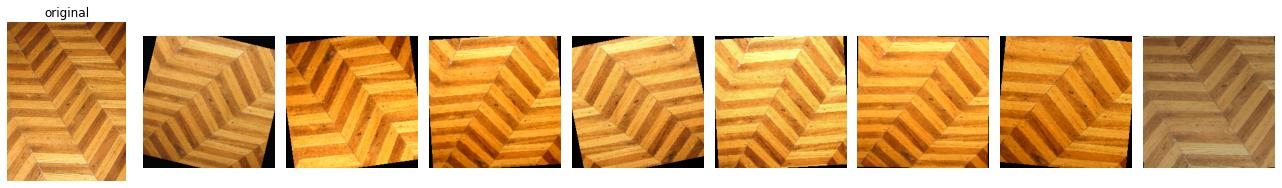

In [12]:
img = load(first.loc["zigzagged"].path, size=400)
mean, std = np.array(IMAGENET_MEAN), np.array(IMAGENET_STD)

def show(t):
    # undo Normalize so the image displays correctly
    return np.clip(t.permute(1, 2, 0).numpy() * std + mean, 0, 1)

fig, axes = plt.subplots(1, 9, figsize=(18, 2.6))
axes[0].imshow(img); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(show(train_tf(img)))
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Finding:** each version is a little different but still clearly the same texture. Vertical flips are fine
because textures have no "up". The small black corners come from the rotation; the model learns to ignore them.

## 9. Summary

| Finding | Decision |
|---|---|
| 47 classes, 40 images each per split, perfectly balanced | Accuracy is a fair metric; no class weights |
| Classes are patterns, and some pairs look alike | Hard task with little data → use a pretrained ResNet18 |
| Image sizes vary (~230–900 px), not square | Resize to 256, center-crop 224 |
| No corrupted files, all RGB | No cleaning needed |
| Colors close to ImageNet (slightly brighter) | Normalize with ImageNet mean/std |
| Only 40 training images per class | Augment the training set (crop, flip, rotate, color jitter) |

**Next:** step 4, a small CNN trained from scratch as a baseline.